# Petals to the Metal: baseline CNN

Kaggle competition: [Petals to the Metal - Flower Classification on TPU](https://www.kaggle.com/competitions/tpu-getting-started).
Classify 224x224 flower photos into 104 classes. The metric is macro F1.

A small custom CNN trained from scratch, no pretrained weights.

## Where it runs

The notebook detects where it runs, so the same file works in three places:

| | Locally | Kaggle GPU | Kaggle TPU |
|---|---|---|---|
| data | unzips `data/tpu-getting-started.zip` | reads `.tfrec` files from `/kaggle/input` | same as GPU |
| device | `mps` / `cuda` / `cpu` | `cuda` | XLA device (`xm.xla_device()`) |
| DataLoader workers | `num_workers=0` (macOS) | `num_workers=4` | `num_workers=4`, `drop_last=True` for train: every new batch shape is a new XLA compilation |
| after each step | - | - | `xm.mark_step()`: XLA builds the graph lazily and runs it at `mark_step` |

Kaggle setup: **Add Input** -> competition `tpu-getting-started`, **Settings** -> **Accelerator** -> **GPU T4 x2** /
**GPU P100** or **TPU**, **Internet** on (for `pip install tfrecord`). A GPU is enough for this model and starts at once,
while TPU sessions often wait in a queue. On Kaggle `submission.csv` is written to `/kaggle/working`.

### Environment

In [ ]:
# where the notebook runs: locally, or on Kaggle with a GPU or a TPU
import os

ON_KAGGLE = os.path.exists("/kaggle/input")

# tfrecord reads .tfrec files without tensorflow; locally it is installed from requirements.txt
if ON_KAGGLE:
    !pip install -q tfrecord

# PyTorch/XLA is only installed on Kaggle TPU machines
try:
    import torch_xla
    import torch_xla.core.xla_model as xm
    USE_TPU = True
except ImportError:
    USE_TPU = False

print(f"on Kaggle: {ON_KAGGLE}, TPU: {USE_TPU}")

### Imports

In [1]:
# standard library
import random
import warnings
import zipfile
from pathlib import Path

# data
import numpy as np
import pandas as pd

# metric
from sklearn.metrics import f1_score

# visualization and progress bars
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

# torch
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader

# images and transforms
from PIL import Image
from torchvision.transforms import v2

# reading .tfrec files without tensorflow
from tfrecord.reader import tfrecord_loader

plt.style.use("seaborn-v0_8-whitegrid")
warnings.filterwarnings("ignore")

### Configs

In [2]:
# hyperparameters and device
SEED = 2026
BATCH_SIZE = 64
NUM_EPOCHS = 50
LR = 1e-3

if USE_TPU:
    DEV = xm.xla_device()
else:
    DEV = torch.device("mps"
    if torch.backends.mps.is_available()
    else "cuda"
    if torch.cuda.is_available()
    else "cpu")

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

print(f"device: {DEV}")


# on a TPU, run the operations collected so far; does nothing on other devices
def sync():
    if USE_TPU:
        xm.mark_step()

device: mps


### Data

In [3]:
# on Kaggle the data is already unpacked under /kaggle/input;
# locally the competition archive is unzipped once into data/
if ON_KAGGLE:
    SRC = next(Path("/kaggle/input").rglob("tfrecords-jpeg-224x224"))
    DST = Path("/tmp/flowers-224")
else:
    DATA_PATH = Path("data")
    ZIP_PATH = DATA_PATH / "tpu-getting-started.zip"
    RAW_PATH = DATA_PATH / "tpu-getting-started"

    if RAW_PATH.exists():
        print(f"{RAW_PATH} already exists, skip unzipping")
    else:
        with zipfile.ZipFile(ZIP_PATH, "r") as ref_zip:
            print(f"Unzipping flowers data in {RAW_PATH} ...")
            ref_zip.extractall(RAW_PATH)

    SRC = RAW_PATH / "tfrecords-jpeg-224x224"
    DST = DATA_PATH / "flowers-224"

data/tpu-getting-started already exists, skip unzipping


### Convert `.tfrec` to `.jpg` and `.csv`

Each `.tfrec` file holds about 800 records: JPEG bytes, image id and class (no class in test).
Every image is written to its own `.jpg` file, ids and labels go to a `.csv`, so the dataset below can read images lazily.

In [4]:
# write every record to DST/<split>/<id>.jpg and its id and label to DST/<split>.csv
def convert_split(split: str, labeled: bool = True):
    out_dir = DST / split
    out_dir.mkdir(parents=True, exist_ok=True)

    description = {"image": "byte", "id": "byte"}
    if labeled:
        description["class"] = "int"

    rows = []
    for tfrec in tqdm(sorted((SRC / split).glob("*.tfrec")), desc=split):
        for rec in tfrecord_loader(str(tfrec), None, description):
            img_id = rec["id"].decode()
            (out_dir / f"{img_id}.jpg").write_bytes(rec["image"])

            row = {"id": img_id}
            if labeled:
                row["label"] = int(rec["class"][0])
            rows.append(row)

    pd.DataFrame(rows).to_csv(DST / f"{split}.csv", index=False)
    print(f"{split}: {len(rows)} images")

In [5]:
# convert train, val and test (a split is skipped if its .csv already exists); test has no labels
for split, labeled in [("train", True), ("val", True), ("test", False)]:
    csv_path = DST / f"{split}.csv"
    if csv_path.exists():
        print(f"{split}: already converted, {len(pd.read_csv(csv_path))} images")
    else:
        convert_split(split, labeled=labeled)

train: already converted, 12753 images
val: already converted, 3712 images
test: already converted, 7382 images


### Custom dataset

Lazy dataset: only the table of ids and labels is kept in memory, an image is read from disk when `__getitem__` asks for it.

In [6]:
# returns (image, label) for train and val, (image, id) for test
class FlowersDataset(Dataset):

    def __init__(self, csv_path, img_path, transform=None):
        self.df = pd.read_csv(csv_path)
        self.img_path = Path(img_path)
        self.transform = transform
        self.has_labels = "label" in self.df.columns

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        image = Image.open(self.img_path / f"{row['id']}.jpg").convert("RGB")

        if self.transform:
            image = self.transform(image)

        if self.has_labels:
            return image, torch.tensor(row["label"], dtype=torch.long)

        return image, row["id"]

### Transforms

In [7]:
# train: light augmentation + ImageNet normalization; val and test: normalization only
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

train_tf = v2.Compose([
    v2.ToImage(),

    v2.RandomResizedCrop(224, scale=(0.7, 1.0)),
    v2.RandomHorizontalFlip(p=0.5),
    v2.RandomRotation(degrees=15),
    v2.ColorJitter(brightness=0.2, contrast=0.2,
                   saturation=0.2, hue=0.02),

    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

eval_tf = v2.Compose([
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

### Datasets

In [8]:
# datasets with transforms for training, validation and test, and train without transforms for plots
train_ds_trans = FlowersDataset(DST / "train.csv", DST / "train", transform=train_tf)
val_ds_trans = FlowersDataset(DST / "val.csv", DST / "val", transform=eval_tf)
test_ds_trans = FlowersDataset(DST / "test.csv", DST / "test", transform=eval_tf)

train_ds_non_trans = FlowersDataset(DST / "train.csv", DST / "train")

print(f"Train: {len(train_ds_trans)} | Val: {len(val_ds_trans)} | Test: {len(test_ds_trans)}")

Train: 12753 | Val: 3712 | Test: 7382


In [9]:
# first rows of the train table: image id and class label
train_ds_trans.df.head()

,id,label
0,338ab7bac,57
1,90ffc5d69,10
2,76feda65b,82
3,416755ace,102
4,4b067b390,94


In [10]:
# number of classes
classes = sorted(train_ds_trans.df["label"].unique())
print(f"Num classes: {len(classes)}")

Num classes: 104


### Class distribution

The classes are heavily imbalanced: from 18 to 782 train images per class.
This is why the metric is macro F1: every class counts equally, so the rare ones matter as much as the common ones.

In [11]:
# number of images per class, from the rarest to the most common
class_counts = train_ds_non_trans.df["label"].value_counts(ascending=True).reset_index()
class_counts

,label,count
0,44,18
1,6,18
2,34,18
3,38,19
4,20,19
...,...,...
99,53,460
100,49,563
101,4,703
102,103,743


### Visualization

In [12]:
# random images in a grid; normalized tensors are converted back to [0, 1] colors before plotting
IMAGENET_MEAN_T = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
IMAGENET_STD_T = torch.tensor(IMAGENET_STD).view(3, 1, 1)

def make_plots(data, rows: int = 3, cols: int = 3, seed: int = SEED):
    random.seed(seed)
    random_indexes = random.sample(range(len(data)), k=rows * cols)
    fig, axes = plt.subplots(rows, cols, figsize=(3 * cols, 3 * rows), squeeze=False)

    for ax, index in zip(axes.flatten(), random_indexes):
        img, label = data[index]

        if isinstance(img, Image.Image):
            ax.imshow(img)
        else:
            img = img * IMAGENET_STD_T + IMAGENET_MEAN_T
            ax.imshow(img.clamp(0, 1).permute(1, 2, 0))

        ax.set_title(f"Class: {label.item()}", fontsize=15)
        ax.axis(False)

    plt.tight_layout()
    plt.show()

Before transforms: the original images.

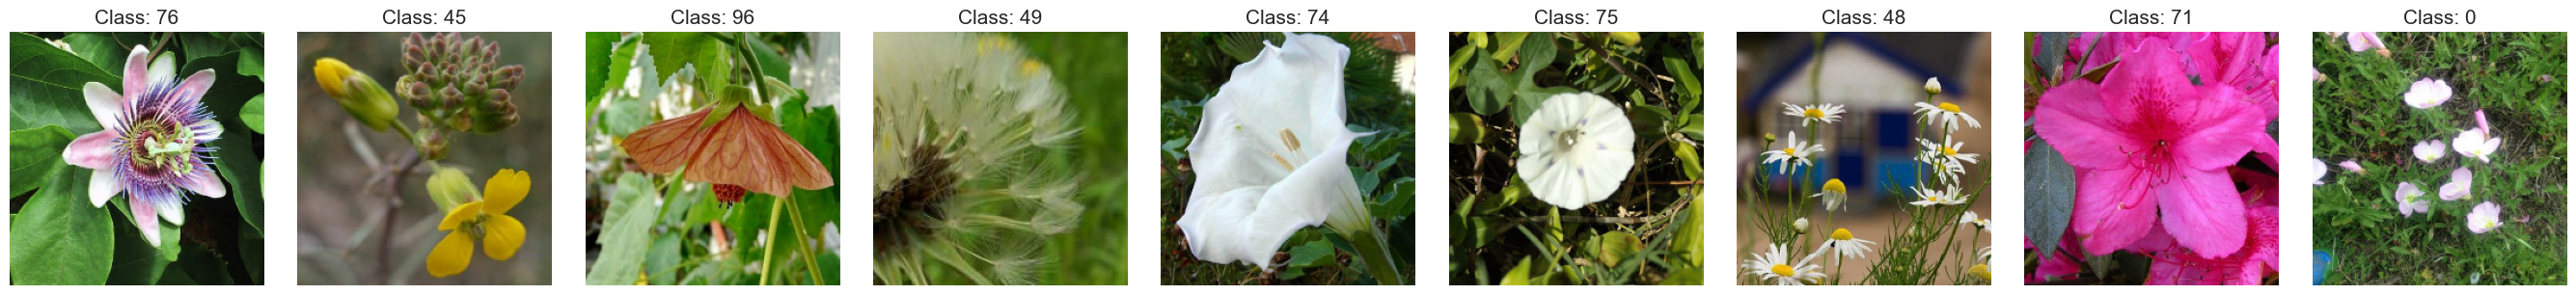

In [13]:
make_plots(train_ds_non_trans, rows=1, cols=9)

After train transforms: the same images (same seed), cropped, flipped, rotated and color-jittered.

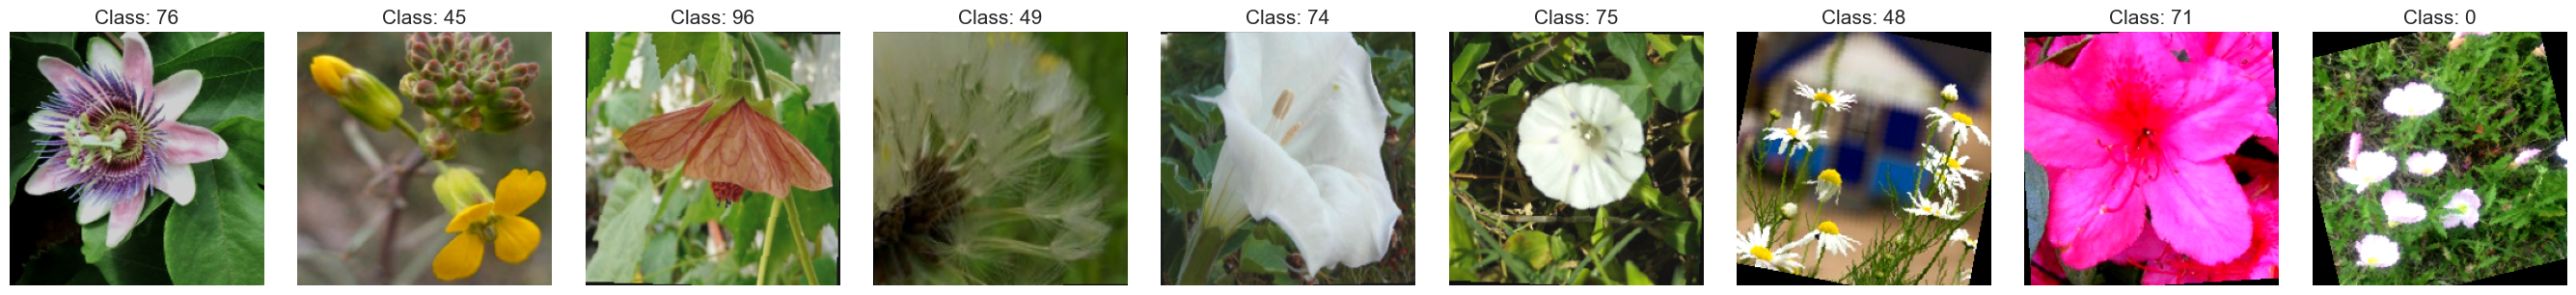

In [14]:
make_plots(train_ds_trans, rows=1, cols=9)

### DataLoaders

In [15]:
# num_workers=NUM_WORKERS locally: on macOS worker processes cannot see a Dataset class defined in the notebook
# drop_last on a TPU: the last train batch is smaller, and every new batch shape is a new XLA compilation
NUM_WORKERS = 4 if ON_KAGGLE else 0

train_loader = DataLoader(
    dataset=train_ds_trans,
    batch_size=BATCH_SIZE,
    shuffle=True,
    drop_last=USE_TPU,
    num_workers=NUM_WORKERS
)

val_loader = DataLoader(
    dataset=val_ds_trans,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS
)

test_loader = DataLoader(
    dataset=test_ds_trans,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS
)

In [16]:
# one batch to check shapes
images, labels = next(iter(train_loader))
print(f"Images: {images.shape} | Labels: {labels.shape}")

Images: torch.Size([64, 3, 224, 224]) | Labels: torch.Size([64])


### Custom CNN

Four blocks, each halves the image and widens the channels: 3x224x224 -> 32x112x112 -> 64x56x56 -> 128x28x28 -> 192x14x14.
Global average pooling turns 192x14x14 into a vector of 192 numbers, and a linear layer maps it to 104 logits.

In [17]:
# conv block: stride-2 conv (downsample) + conv, each followed by BatchNorm and SiLU
class CustomFlowersModelv0(nn.Module):

    def __init__(self, input_shape: int = 3, num_classes: int = 104):
        super().__init__()

        def conv_block(in_f, out_f):
            return nn.Sequential(
                nn.Conv2d(in_channels=in_f, out_channels=out_f, kernel_size=3, stride=2, padding=1, bias=False),
                nn.BatchNorm2d(out_f),
                nn.SiLU(),
                nn.Conv2d(in_channels=out_f, out_channels=out_f, kernel_size=3, stride=1, padding=1, bias=False),
                nn.BatchNorm2d(out_f),
                nn.SiLU()
            )

        self.features = nn.Sequential(
            conv_block(in_f=input_shape, out_f=32),
            conv_block(in_f=32, out_f=64),
            conv_block(in_f=64, out_f=128),
            conv_block(in_f=128, out_f=192)
        )
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten(),
            nn.Linear(192, num_classes)
        )

    def forward(self, x):
        return self.classifier(self.features(x))

In [18]:
# fixed seed before creating the model, so the initial weights are the same on every run
torch.manual_seed(SEED)

custom_model = CustomFlowersModelv0(
    input_shape=3,
    num_classes=len(classes)).to(DEV)

print(f"Parameters: {sum(p.numel() for p in custom_model.parameters()):,}")

Parameters: 861,256


### Train step

In [19]:
# one epoch of training; loss, macro F1 and accuracy are computed over the whole epoch
def train_step(model: torch.nn.Module,
               dataloader: torch.utils.data.DataLoader,
               loss_fn: torch.nn.Module,
               optimizer: torch.optim.Optimizer,
               device: torch.device):

    model.train()
    total_loss, correct = 0, 0
    all_preds, all_targets = [], []

    for X, y in dataloader:
        X, y = X.to(device), y.to(device)
        logits = model(X)
        loss = loss_fn(logits, y)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        sync()

        total_loss += loss.item() * len(y)
        y_preds = torch.argmax(logits, dim=1)
        correct += (y_preds == y).sum().item()
        all_preds.append(y_preds.cpu())
        all_targets.append(y.cpu())

    all_preds = torch.cat(all_preds).numpy()
    all_targets = torch.cat(all_targets).numpy()

    n = len(all_targets)
    train_loss = total_loss / n
    train_f1 = f1_score(all_targets, all_preds, average="macro")
    train_acc = correct / n

    return train_loss, train_f1, train_acc

### Eval step

In [20]:
# one pass over validation without gradients; same metrics as in train_step
def eval_step(model: torch.nn.Module,
              dataloader: torch.utils.data.DataLoader,
              loss_fn: torch.nn.Module,
              device: torch.device):

    model.eval()
    total_loss, correct = 0, 0
    all_preds, all_targets = [], []

    # no_grad rather than inference_mode: inference tensors are not supported by XLA
    with torch.no_grad():
        for X, y in dataloader:
            X, y = X.to(device), y.to(device)
            logits = model(X)
            loss = loss_fn(logits, y)
            sync()

            total_loss += loss.item() * len(y)
            y_preds = torch.argmax(logits, dim=1)
            correct += (y_preds == y).sum().item()
            all_preds.append(y_preds.cpu())
            all_targets.append(y.cpu())

    all_preds = torch.cat(all_preds).numpy()
    all_targets = torch.cat(all_targets).numpy()

    n = len(all_targets)
    eval_loss = total_loss / n
    eval_f1 = f1_score(all_targets, all_preds, average="macro")
    eval_acc = correct / n

    return eval_loss, eval_f1, eval_acc

### Full step (train step + eval step)

The best epoch is chosen by val macro F1, the competition metric. Its weights are loaded back into the model at the end.

In [21]:
# train for several epochs, evaluate on val after each one and keep the weights of the best epoch
def full_step(model: torch.nn.Module,
              train_dataloader: torch.utils.data.DataLoader,
              val_dataloader: torch.utils.data.DataLoader,
              loss_fn: torch.nn.Module,
              optimizer: torch.optim.Optimizer,
              epochs: int,
              device: torch.device,
              scheduler: torch.optim.lr_scheduler.LRScheduler):

    results = {"train_loss": [], "train_f1": [], "train_acc": [],
               "val_loss": [],   "val_f1": [],   "val_acc": []}

    best_f1 = 0.0
    best_state = None
    best_epoch = 0

    for epoch in tqdm(range(epochs)):
        train_loss, train_f1, train_acc = train_step(model=model,
                                                     dataloader=train_dataloader,
                                                     loss_fn=loss_fn,
                                                     optimizer=optimizer,
                                                     device=device)
        val_loss, val_f1, val_acc = eval_step(model=model,
                                              dataloader=val_dataloader,
                                              loss_fn=loss_fn,
                                              device=device)

        scheduler.step()

        if val_f1 > best_f1:
            best_f1 = val_f1
            best_epoch = epoch + 1
            # copied to the CPU, which works for every device including the TPU
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

        print(f"Epoch {epoch+1:2d} | "
              f"Train Loss {train_loss:.3f} F1 {train_f1:.3f} Acc {train_acc:.3f} | "
              f"Val Loss {val_loss:.3f} F1 {val_f1:.3f} Acc {val_acc:.3f}"
              f"{'  <- best' if best_epoch == epoch + 1 else ''}")

        results["train_loss"].append(train_loss)
        results["train_f1"].append(train_f1)
        results["train_acc"].append(train_acc)
        results["val_loss"].append(val_loss)
        results["val_f1"].append(val_f1)
        results["val_acc"].append(val_acc)

    model.load_state_dict(best_state)
    print(f"Best Val F1 {best_f1:.3f} on Epoch {best_epoch}")

    return results

### Class weights (tried, not used)

Balanced weights `N / (K * n_c)` in `CrossEntropyLoss(weight=...)` push the model towards the rare classes.
With this small model they made things worse: val macro F1 dropped from 0.64 to 0.42 after 50 epochs,
because the model spends its little capacity on classes with 18 images. The loss below is unweighted.

In [22]:
# balanced class weights, the same formula as sklearn compute_class_weight("balanced")
counts = train_ds_trans.df["label"].value_counts().sort_index()
class_weights = counts.sum() / (len(counts) * counts)
class_weights = torch.tensor(class_weights.values, dtype=torch.float32).to(DEV)

### Loss, optimizer, scheduler

In [23]:
# cross-entropy, AdamW and cosine decay of the learning rate over all epochs (scheduler.step() once per epoch)
loss_fn = torch.nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(custom_model.parameters(), lr=LR)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer=optimizer, T_max=NUM_EPOCHS)

### Training

In [24]:
# fixed seed for the order of batches and the random augmentations
torch.manual_seed(SEED)

results = full_step(model=custom_model,
                    train_dataloader=train_loader,
                    val_dataloader=val_loader,
                    loss_fn=loss_fn,
                    optimizer=optimizer,
                    epochs=NUM_EPOCHS,
                    device=DEV,
                    scheduler=scheduler)

  0%|          | 0/50 [00:00<?, ?it/s]

KeyboardInterrupt: 

### Learning curves

Train metrics are measured on augmented images while the model is still changing during the epoch,
so they are not directly comparable with val. What matters is the val curve and the gap between the two.

In [ ]:
# loss and macro F1 per epoch, train vs val
epochs = range(1, len(results["train_loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

for ax, metric in zip(axes, ["loss", "f1"]):
    ax.plot(epochs, results[f"train_{metric}"], label="train")
    ax.plot(epochs, results[f"val_{metric}"], label="val")
    ax.set_title(metric)
    ax.set_xlabel("epoch")
    ax.legend()

plt.tight_layout()
plt.show()

### Prediction

In [ ]:
# predicted class for every test image, in the order of test.csv (shuffle=False)
def make_predictions(model: torch.nn.Module,
                     dataloader: torch.utils.data.DataLoader,
                     device: torch.device):

    model.eval()
    predictions = []

    with torch.no_grad():
        for X, _ in dataloader:
            X = X.to(device)
            logits = model(X)
            sync()
            y_preds = torch.argmax(logits, dim=1)
            predictions.append(y_preds.cpu())

    return torch.cat(predictions)

In [ ]:
test_pred = make_predictions(model=custom_model,
                             dataloader=test_loader,
                             device=DEV)

### Submission

In [ ]:
# id and predicted label for every test image
submission = pd.DataFrame({"id": test_ds_trans.df["id"],
                           "label": test_pred.numpy()})

submission.to_csv("submission.csv", index=False)
submission